In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 300

# Load raw survey dataset
df_raw = pd.read_csv('data/P5_Dependencies_September 8, 2026_10.40.csv')

print(f"Dataset loaded successfully. Total responses: {df_raw.shape[0]}, Total columns: {df_raw.shape[1]}")
df_raw.head(2)

Dataset loaded successfully. Total responses: 53, Total columns: 28


,Start Date,End Date,Response Type,IP Address,Progress,Duration (in seconds),Finished,Recorded Date,Response ID,Location Latitude,...,How long have you been working with p5.js?,"Generative art sketches often rely on external factors, ranging from libraries and custom assets to hardware capabilities, browser APIs, and runtime environments. We have developed a taxonomy to systematically categorize and analyze these dependencies to better understand how p5.js projects are built, maintained, and preserved.\n\nYour feedback will help us validate and refine this taxonomy so it accurately reflects the real-world practices of the p5.js community.\n\n\n\nInstructions\n\n\tReview the Taxonomy: Below, you will find the proposed taxonomy, including each proposed category, and its definition.\n\tEvaluate Clarity & Completeness: You will be asked to rate how clear the definitions are and whether any dependency types are missing.\n\tInsights: Short text boxes will be available to suggest missing edge cases, highlight overlapping categories, or offer improvements. - How easy the categories are to understand","Generative art sketches often rely on external factors, ranging from libraries and custom assets to hardware capabilities, browser APIs, and runtime environments. We have developed a taxonomy to systematically categorize and analyze these dependencies to better understand how p5.js projects are built, maintained, and preserved.\n\nYour feedback will help us validate and refine this taxonomy so it accurately reflects the real-world practices of the p5.js community.\n\n\n\nInstructions\n\n\tReview the Taxonomy: Below, you will find the proposed taxonomy, including each proposed category, and its definition.\n\tEvaluate Clarity & Completeness: You will be asked to rate how clear the definitions are and whether any dependency types are missing.\n\tInsights: Short text boxes will be available to suggest missing edge cases, highlight overlapping categories, or offer improvements. - How well the categories cover all p5.js dependency types","What specific p5.js libraries, external assets, runtime/hardware dependencies, or code-level patterns are missing or unaddressed by this taxonomy?","Which specific categories did you find ambiguous, difficult to distinguish, or overlapping? Please share any suggestions for renaming or regrouping them",How confident would you feel applying this taxonomy to categorize or audit dependencies in your own p5.js projects?,Did you notice any overlap where a single dependency type could fit into multiple categories simultaneously?,"Which categories overlapped, and under what circumstances?","We want to ensure that the proposed taxonomy is as useful and comprehensive as possible. p5.js projects often involve unique setups (e.g., WebGL shaders, node packages, hardware inputs like webcams/MIDI, or iframe embedding).\n\nBased on your experience developing with p5.js, are there edge cases in your workflow that this taxonomy fails to accommodate?","Do you have any final thoughts, suggestions, or experiences regarding p5.js dependencies that we haven't covered? We’d love to hear your feedback."
0,2026-08-03 09:14:49,2026-08-03 09:41:31,IP Address,184.163.97.162,100,1602,True,2026-08-03 09:41:31,R_5rP22JQqkQEs1r5,45.5329,...,1 to 3 years,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I find 'Determinism and generated state' a bit...,NaN
1,2026-08-05 12:02:56,2026-08-05 12:17:13,IP Address,187.188.10.57,100,857,True,2026-08-05 12:17:14,R_58cmD7YdrXJlDVv,19.4177,...,4 to 6 years,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sadfa


In [22]:
column_mapping = {
    df_raw.columns[0]: 'start_date',
    df_raw.columns[1]: 'end_date',
    df_raw.columns[2]: 'response_type',
    df_raw.columns[3]: 'ip_address',
    df_raw.columns[4]: 'progress',
    df_raw.columns[5]: 'duration_sec',
    df_raw.columns[6]: 'finished',
    df_raw.columns[7]: 'recorded_date',
    df_raw.columns[8]: 'response_id',
    df_raw.columns[9]: 'latitude',
    df_raw.columns[10]: 'longitude',
    df_raw.columns[11]: 'distribution_channel',
    df_raw.columns[12]: 'user_language',
    df_raw.columns[13]: 'consent',
    df_raw.columns[14]: 'occupation',
    df_raw.columns[15]: 'occupation_other',
    df_raw.columns[16]: 'sector',
    df_raw.columns[17]: 'sector_other',
    df_raw.columns[18]: 'p5js_experience',
    df_raw.columns[19]: 'rating_clarity',
    df_raw.columns[20]: 'rating_completeness',
    df_raw.columns[21]: 'missing_dependencies',
    df_raw.columns[22]: 'ambiguous_categories',
    df_raw.columns[23]: 'confidence_applying',
    df_raw.columns[24]: 'category_overlap_notice',
    df_raw.columns[25]: 'overlapping_categories_detail',
    df_raw.columns[26]: 'edge_cases_unaccommodated',
    df_raw.columns[27]: 'final_thoughts'
}

df = df_raw.rename(columns=column_mapping)

# Convert numeric fields
df['duration_sec'] = pd.to_numeric(df['duration_sec'], errors='coerce')
df['progress'] = pd.to_numeric(df['progress'], errors='coerce')
df['finished'] = df['finished'].astype(bool)

# Filtering overview
total_records = len(df)
consented = df['consent'].str.contains('consent', case=False, na=False).sum()
completed = df['finished'].sum()

print(f"Data Quality Filtering Summary:")
print(f" - Raw Submissions: {total_records}")
print(f" - Consented Submissions: {consented}")
print(f" - Fully Completed Surveys (Progress = 100%): {completed}")

Data Quality Filtering Summary:
 - Raw Submissions: 53
 - Consented Submissions: 52
 - Fully Completed Surveys (Progress = 100%): 14


# Demographics

/var/folders/rm/jpz9s5s53h1gyb3l6pg_h57r0000gn/T/ipykernel_36187/1941873562.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=occupation_counts.values, y=occupation_counts.index, ax=axes[0], palette="Blues_r")
/var/folders/rm/jpz9s5s53h1gyb3l6pg_h57r0000gn/T/ipykernel_36187/1941873562.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=exp_filtered.values, y=exp_filtered.index, ax=axes[1], palette="Greens_r")


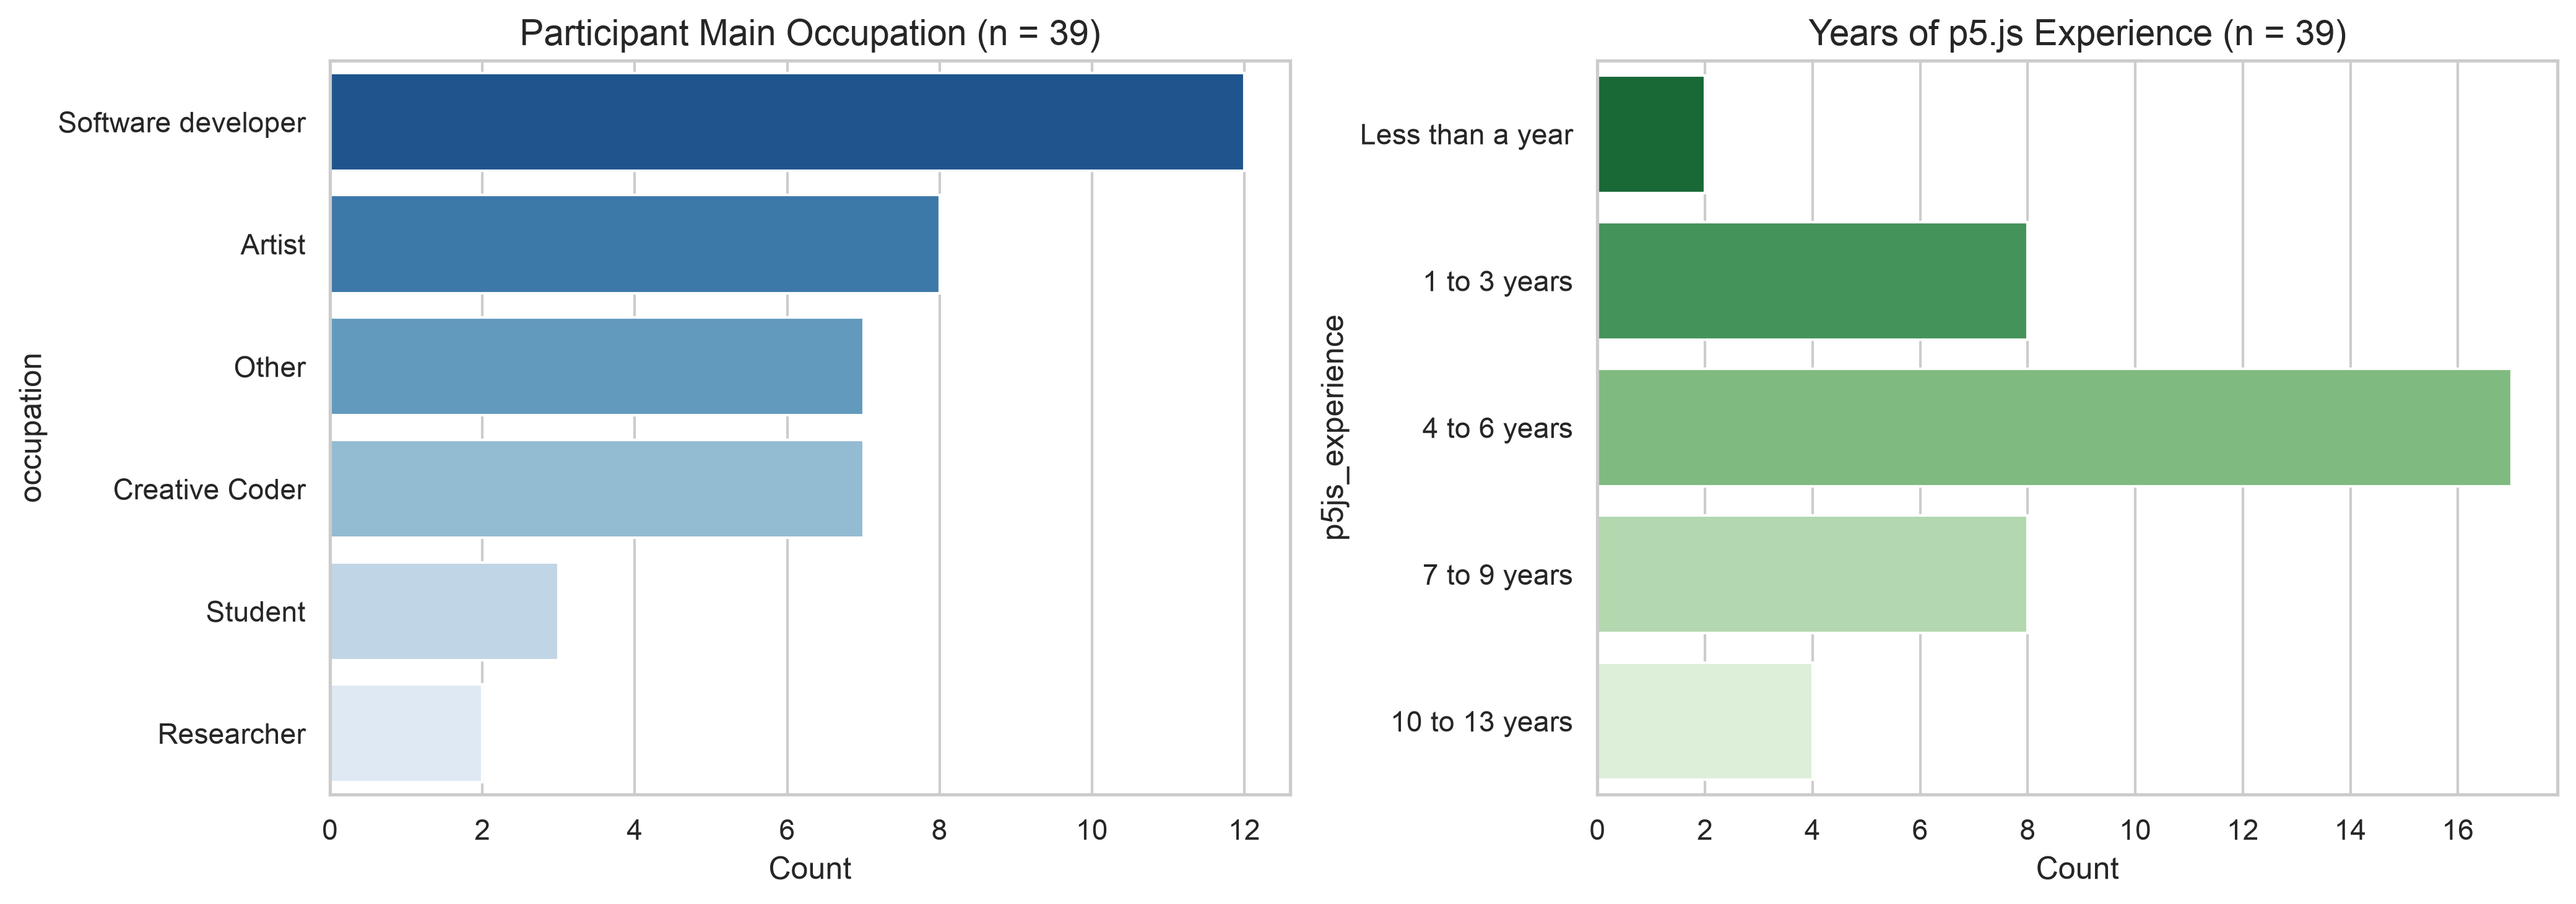

In [23]:
occupation_counts = df['occupation'].dropna().value_counts()
sector_counts = df['sector'].dropna().value_counts()
exp_counts = df['p5js_experience'].dropna().value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=occupation_counts.values, y=occupation_counts.index, ax=axes[0], palette="Blues_r")
axes[0].set_title("Participant Main Occupation (n = 39)")
axes[0].set_xlabel("Count")

exp_order = ['Less than a year', '1 to 3 years', '4 to 6 years', '7 to 9 years', '10 to 13 years']
exp_filtered = exp_counts.reindex([e for e in exp_order if e in exp_counts.index])

sns.barplot(x=exp_filtered.values, y=exp_filtered.index, ax=axes[1], palette="Greens_r")
axes[1].set_title("Years of p5.js Experience (n = 39)")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.savefig('demographics_experience.png', bbox_inches='tight')
plt.show()

# Quantitative Results

In [24]:
eval_df = df[['rating_clarity', 'rating_completeness', 'confidence_applying', 'category_overlap_notice']].dropna(how='all')

print("=== Taxonomy Category Clarity ===")
print(eval_df['rating_clarity'].value_counts(dropna=True))

print("\n=== Taxonomy Coverage Completeness ===")
print(eval_df['rating_completeness'].value_counts(dropna=True))

print("\n=== Application Confidence ===")
print(eval_df['confidence_applying'].value_counts(dropna=True))

print("\n=== Category Overlap Observed ===")
print(eval_df['category_overlap_notice'].value_counts(dropna=True))

=== Taxonomy Category Clarity ===
rating_clarity
Very clear          8
Moderately clear    3
Extremely clear     2
Not at all clear    1
Name: count, dtype: int64

=== Taxonomy Coverage Completeness ===
rating_completeness
Very complete          7
Moderately complete    6
Not at all complete    1
Name: count, dtype: int64

=== Application Confidence ===
confidence_applying
Moderately confident    6
Very confident          4
Not at all confident    2
Slightly confident      1
Extremely confident     1
Name: count, dtype: int64

=== Category Overlap Observed ===
category_overlap_notice
Yes       7
Unsure    4
No        3
Name: count, dtype: int64


/var/folders/rm/jpz9s5s53h1gyb3l6pg_h57r0000gn/T/ipykernel_36187/3039348.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='rating_clarity', data=df, order=[o for o in clarity_order if o in df['rating_clarity'].values], ax=axes[0], palette="light:b")
/var/folders/rm/jpz9s5s53h1gyb3l6pg_h57r0000gn/T/ipykernel_36187/3039348.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='rating_completeness', data=df, order=[o for o in completeness_order if o in df['rating_completeness'].values], ax=axes[1], palette="light:b")
/var/folders/rm/jpz9s5s53h1gyb3l6pg_h57r0000gn/T/ipykernel_36187/3039348.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be rem

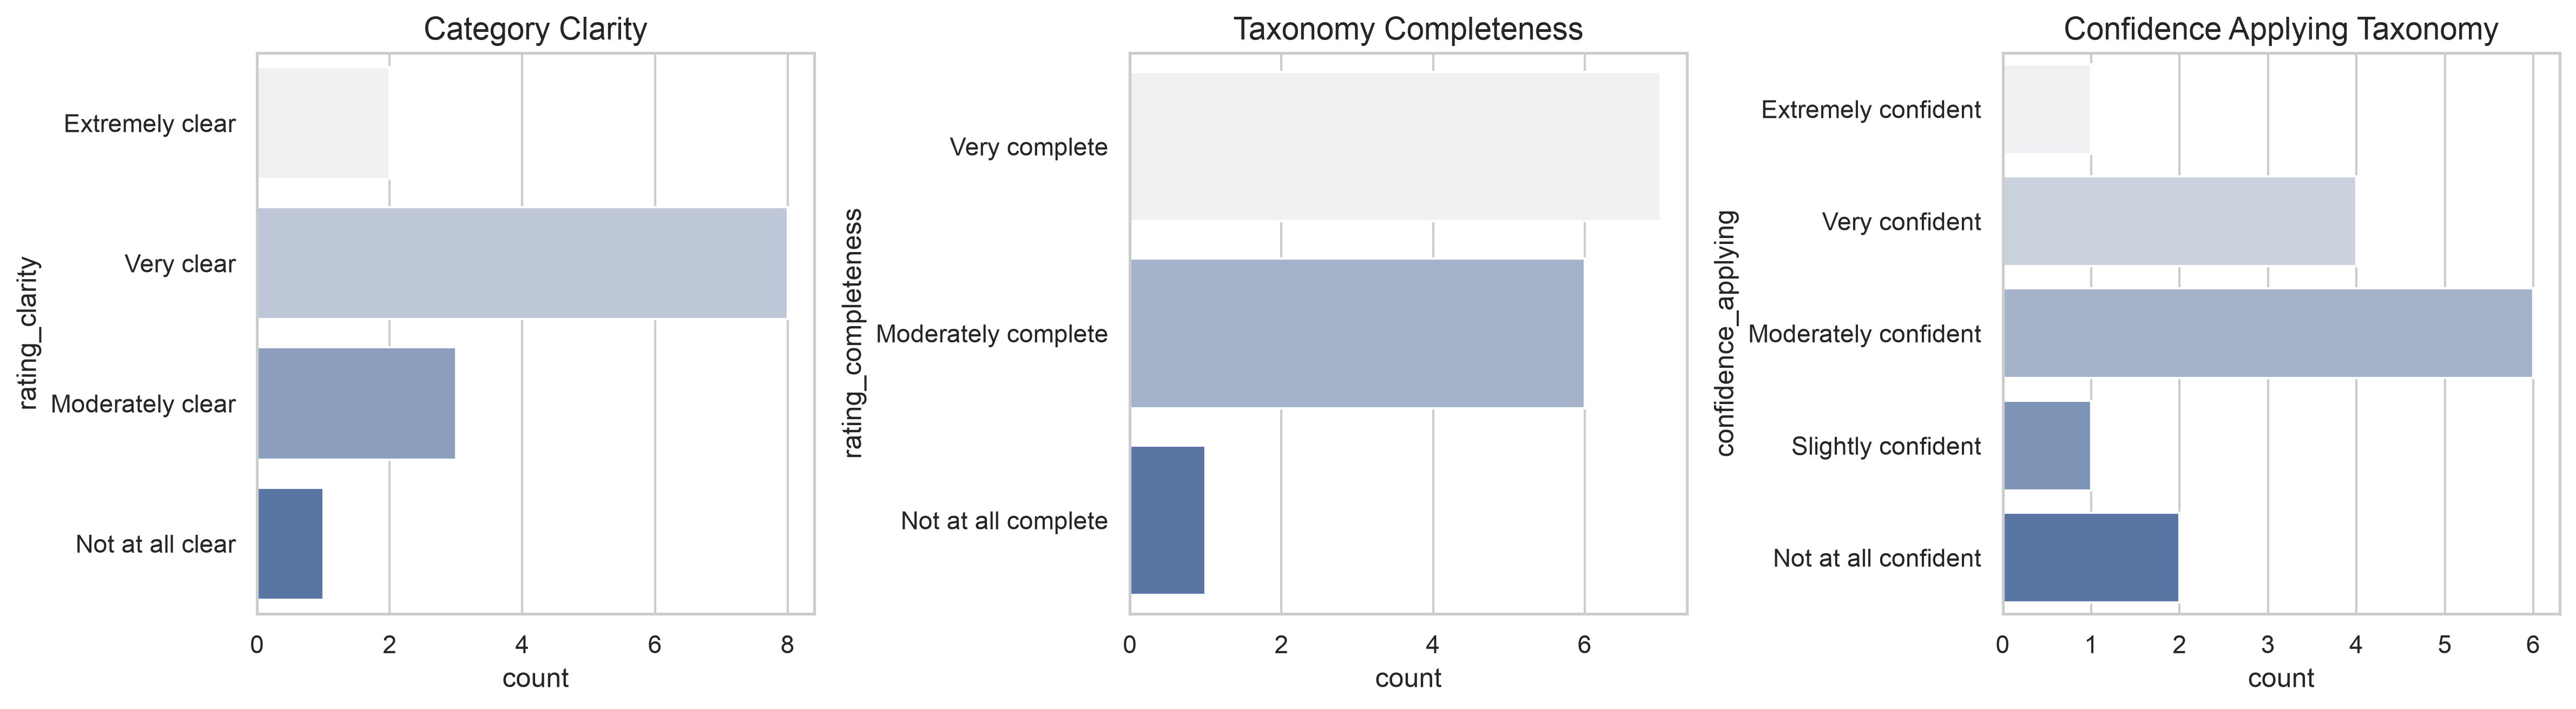

In [32]:
sns.color_palette("Blues", as_cmap=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

clarity_order = ['Extremely clear', 'Very clear', 'Moderately clear', 'Not at all clear']
completeness_order = ['Very complete', 'Moderately complete', 'Not at all complete']
confidence_order = ['Extremely confident', 'Very confident', 'Moderately confident', 'Slightly confident', 'Not at all confident']

sns.countplot(y='rating_clarity', data=df, order=[o for o in clarity_order if o in df['rating_clarity'].values], ax=axes[0], palette="light:b")
axes[0].set_title("Category Clarity")

sns.countplot(y='rating_completeness', data=df, order=[o for o in completeness_order if o in df['rating_completeness'].values], ax=axes[1], palette="light:b")
axes[1].set_title("Taxonomy Completeness")

sns.countplot(y='confidence_applying', data=df, order=[o for o in confidence_order if o in df['confidence_applying'].values], ax=axes[2], palette="light:b")
axes[2].set_title("Confidence Applying Taxonomy")

plt.tight_layout()
plt.savefig('taxonomy_ratings.png', bbox_inches='tight')
plt.show()

# Qualitative